# Reunião de 13/11/2026: partindo do que combinamos em 30/09

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andreydeps/tcc-politica-industrial-sc/blob/main/notebooks/reuniao_2026-11-13.ipynb)

TCC: política industrial nos PPAs de Santa Catarina (2004-2027). Este notebook só **lê os resultados já salvos** em `saidas/` (não refaz extração nem análise). O pipeline completo está em `TCC.ipynb` e nos `scripts/`.

| Combinado | Feito | Resultado |
|---|---|---|
| Dicionário de palavras (lexical matching) | Léxico com 5 sementes, expandido | 20 termos em 5 dimensões; 9 descartados e 9 em espera |
| Snowballing: usar coocorrência para achar palavras-chave melhores | Expansão por coocorrência e por vetores de palavras | 33 candidatos avaliados, 20 termos no léxico |
| Comparar as palavras-chave com todas as palavras (circularidade) | Permutação, 1.000 léxicos aleatórios, semente contra expansão, PPA inteiro | Só competitividade muda além do acaso; resiste aos testes de palavras; não aparece no PPA inteiro |
| Ver se SC usa os ODS | Busca pela sigla e pelo vocabulário das 169 metas | Zero menções; o vocabulário não cresce depois de 2015; não serve como léxico de referência |
| Clusterizar os termos antes do topic modeling | Agrupamento das palavras e LDA sobre os grupos | Estável entre rodadas, mas um programa a mais muda os tópicos; o LDA sai dos resultados |
| Ligar as palavras que mudaram a tipos de política (crédito, clusters) | Busca dos instrumentos nas ações dos programas e soma dos valores orçados | Os instrumentos aparecem nas ações, não nos objetivos; sem folha e emendas, a parcela da política industrial e do crédito a empresas cai enquanto o discurso sobe |
| Achar APLs, clusters, educação tecnológica e como são promovidos | Mesma busca nas ações | APL até 2012-2015, incubadoras até 2016-2019; qualificação quase só de gestores públicos e agricultores; incentivo fiscal nunca aparece (fica na LDO) |
| Figura conceitual de como o texto é classificado | Feita | Figura do método e rascunho da metodologia |
| Separar o que é política (programa) do que é seção (campo do texto) | Incluído no rascunho da metodologia | Distinção definida; falta fechar na escrita |

Parciais: PPAs mais antigos e contexto histórico. Não feitos: benchmark de estados e clusterização de pequenos produtores rurais.

In [1]:
# No Google Colab: baixa o repositório com os resultados. No computador local, não faz nada.
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/tcc"):
        !git clone -q https://github.com/andreydeps/tcc-politica-industrial-sc.git /content/tcc
    %cd /content/tcc

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
S = RAIZ / "saidas"
PER = ["2004-2007", "2008-2011", "2012-2015", "2016-2019", "2020-2023", "2024-2027"]

def fig(nome, largura=720):
    display(Image(filename=str(S / nome), width=largura))

def tabela(df, casas=1):
    # p-valores com 3 casas; demais números com `casas` casas; vírgula decimal
    num = lambda c, k: (lambda v: f"{v:,.{k}f}".replace(",", "X").replace(".", ",").replace("X", "."))
    fmt = {c: num(c, 0 if pd.api.types.is_integer_dtype(df[c]) else 3 if str(c) == "p" or str(c).startswith("p ") else casas)
           for c in df.select_dtypes("number").columns}
    display(df.style.hide(axis="index").format(fmt))

## 1. Corpus e janela temporal

*Combinado: incluir PPAs mais antigos.*

O PPA 2004-2007 entrou. O 2000-2003 (Lei 11.357/2000) e o 1996-1999 (Lei 10.057/1995) não estão disponíveis na SEF e foram pedidos à ALESC. Mesmo o 2004-2007 já está dentro do boom das commodities, então a janela ainda não cobre um período "antes".

Corpus atual: 6 PPAs, 514 programas no total, **42 pares programa-PPA** selecionados como política industrial (19 códigos distintos; o 2004-2007 usa outra numeração). Texto analisado: objetivo + justificativa, lematizado (só substantivos, verbos e adjetivos). A unidade das medidas é **ocorrências por mil lemas**.

In [3]:
corpus = pd.read_csv(S / "corpus_programas.csv", dtype={"codigo": str})
lemas = corpus["texto_lematizado"].fillna("").str.split().str.len()
tabela(corpus.assign(lemas=lemas).groupby("periodo", as_index=False)
       .agg(pares=("codigo", "size"), lemas=("lemas", "sum")).rename(columns={"periodo": "PPA"}), 0)

PPA,pares,lemas
2004-2007,9,168
2008-2011,4,146
2012-2015,8,317
2016-2019,7,298
2020-2023,7,326
2024-2027,7,275


## 2. Léxico e snowballing

*Combinados: dicionário de palavras (lexical matching) e expansão por coocorrência.*

Partimos de 5 sementes, uma por dimensão. A expansão buscou candidatos por coocorrência com as sementes e por vizinhança nos vetores de palavras do spaCy. Foram 33 candidatos avaliados; o léxico final tem 20 termos em 5 dimensões.

In [4]:
lx = pd.read_csv(S / "lexico_validado.csv")
ok = lx[lx.decisao.isin(["entra", "variante"])]
tabela(ok.groupby("dimensao", as_index=False).agg(termos=("termo", ", ".join), n=("termo", "size"))
       .rename(columns={"dimensao": "dimensão"}), 0)

dimensão,termos,n
competitividade e produção,"competitividade, produtividade, competitivo, diversificação",4
digital,computador,1
inovação e tecnologia,"inovação, tecnologia, modernização, tecnológico",4
inserção internacional,"internacional, exportação, mundial, global, comercial",5
trabalho e renda,"emprego, qualificação, trabalhador, empregar, trabalho, renda",6


Nove descartados (genéricos ou fragmentos: economia, micro, provedora, sustentabilidade, desenvolvimento, criação, empresa, nacional, governamental) e nove em espera (digital, qualidade, mercado, negócio, investimento, cooperação, empresarial, setor, regional). A dimensão digital ficou só com "computador".

## 3. O que muda além do acaso

Para cada dimensão do léxico (20 termos), a taxa por mil lemas em cada PPA.

Como os textos são curtos, toda dimensão oscila entre os PPAs. O teste sorteia os programas entre os PPAs milhares de vezes; só conta como mudança o que raramente aparece nesses sorteios.

Testes:
- **permutação** (3.000 sorteios do PPA de cada programa): p da amplitude (máx − mín, relativa à média) e da tendência no tempo (Spearman);
- **1.000 léxicos aleatórios** com palavras de frequência parecida: % que a dimensão supera.

Com 5 dimensões, o limite corrigido (Bonferroni) é 0,01.

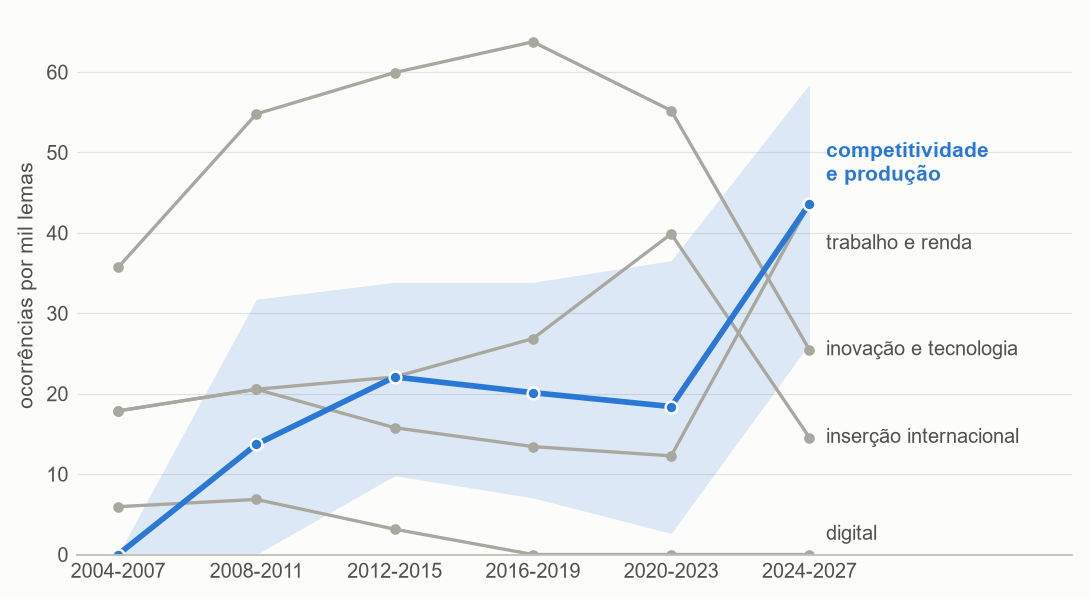

In [5]:
fig("doc_lexico.png")

In [6]:
t = pd.read_csv(S / "indice_lexico_programas_testes.csv")
t = t[t.dimensao != "léxico inteiro"]
tabela(t[["dimensao", "ocorrencias", "p_perm_amplitude", "p_perm_tendencia",
          "pct_lexicos_aleatorios_amplitude", "pct_lexicos_aleatorios_tendencia"]]
       .rename(columns={"dimensao": "dimensão", "ocorrencias": "ocorrências", "p_perm_amplitude": "p amplitude",
                        "p_perm_tendencia": "p tendência", "pct_lexicos_aleatorios_amplitude": "% aleatórios (amplitude)",
                        "pct_lexicos_aleatorios_tendencia": "% aleatórios (tendência)"}))

dimensão,ocorrências,p amplitude,p tendência,% aleatórios (amplitude),% aleatórios (tendência)
competitividade e produção,33,"0,004","0,099","99,7","88,4"
digital,3,"0,643","0,020","36,8","100,0"
inovação e tecnologia,77,"0,919","1,000","43,7","6,2"
inserção internacional,38,"0,858","0,816","53,7","30,0"
trabalho e renda,31,"0,826","0,916","72,4","20,7"


**Leitura:** só competitividade e produção varia além do acaso (p = 0,004; acima de 99,7% dos léxicos aleatórios na amplitude). A **tendência contínua não é significativa** (p = 0,10): o que existe é um patamar de 14 a 22 por mil entre 2008 e 2023 e uma alta em 2024-2027. "Digital" com p = 0,02 na tendência são 3 ocorrências num programa só.

## 4. Circularidade: a alta vem da semente e se concentra no último PPA

*Combinado: comparar as palavras-chave com todas as palavras.*

A preocupação era o léxico achar só o que já se esperava. Três respostas:
- **(a)** a dimensão competitividade varia mais do que 99,7% de 1.000 léxicos montados com palavras de frequência parecida;
- **(b)** os termos que entraram pela expansão, sozinhos, não variam (p = 0,62); a semente sozinha varia (p = 0,002);
- **(c)** das 5 sementes, só uma passou no teste.

Os termos novos entraram por coocorrência com "competitividade" e poderiam só repetir a trajetória dela. Aqui separados. "p último PPA" testa 2024-2027 contra os cinco PPAs anteriores juntos (5.000 permutações).

In [7]:
r = pd.read_csv(S / "robustez_competitividade.csv")
linhas = {"selecionados | dimensão": "dimensão (4 termos)",
          "selecionados | só a semente": "só 'competitividade'",
          "selecionados | só os termos novos": "só os 3 termos novos",
          "selecionados sem o 0353 | dimensão": "dimensão, sem o 0353",
          "selecionados sem o 0353 | só a semente": "só 'competitividade', sem o 0353"}
x = r[r.teste.isin(linhas)].assign(teste=lambda d: d.teste.map(linhas))
tabela(x[["teste"] + [f"{p} taxa" for p in PER] + ["p_amplitude", "p_ultimo_maior"]]
       .rename(columns={**{f"{p} taxa": p[2:4] + "-" + p[-2:] for p in PER},
                        "p_amplitude": "p variação", "p_ultimo_maior": "p último PPA"}))

teste,04-07,08-11,12-15,16-19,20-23,24-27,p variação,p último PPA
dimensão (4 termos),"0,0","13,7","22,1","20,1","18,4","43,6","0,005","0,003"
só 'competitividade',"0,0","6,8","9,5","10,1","9,2","29,1","0,002","0,001"
só os 3 termos novos,"0,0","6,8","12,6","10,1","9,2","14,5","0,618","0,213"
"dimensão, sem o 0353","0,0","13,7","22,1","20,1","18,4","36,9","0,022","0,024"
"só 'competitividade', sem o 0353","0,0","6,8","9,5","10,1","9,2","27,6","0,006","0,001"


In [8]:
ocorr = r.set_index("teste").loc["selecionados | dimensão", [f"{p} ocorr/lemas" for p in PER]]
tabela(pd.DataFrame([ocorr.values], columns=PER).assign(medida="ocorrências / lemas")[["medida"] + PER])

medida,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
ocorrências / lemas,0/168,2/146,7/317,6/298,6/326,12/275


**Leitura:** a semente sozinha dá o resultado (p = 0,002); os termos novos sozinhos não variam (p = 0,62), então **a expansão do léxico não fabrica o achado**. O 0353 (Incentivo à Competitividade da Indústria, do Comércio e do Serviço), que só existe em 2024-2027, reforça, mas sem ele continua. Cuidado com o tamanho: **12 ocorrências em 275 lemas** no último PPA. Último PPA contra os anteriores: +27 por mil (IC 95% de 8 a 43).

## 5. A lista de programas importa?

A seleção foi feita lendo nome e objetivo. Três testes sobre a lista e um fora dela.

In [9]:
tu = pd.read_csv(S / "competitividade_tira_um.csv")
tu = tu[tu.retirado != "(nenhum)"]
tabela(tu.groupby("alvo", as_index=False).agg(casos=("p_perm", "size"), pior_p=("p_perm", "max"))
       .rename(columns={"alvo": "tirando um par de cada vez", "pior_p": "p pior caso"}), 0)

tirando um par de cada vez,casos,p pior caso
dimensão competitividade e produção,42,"0,027"
termo competitividade,42,"0,009"


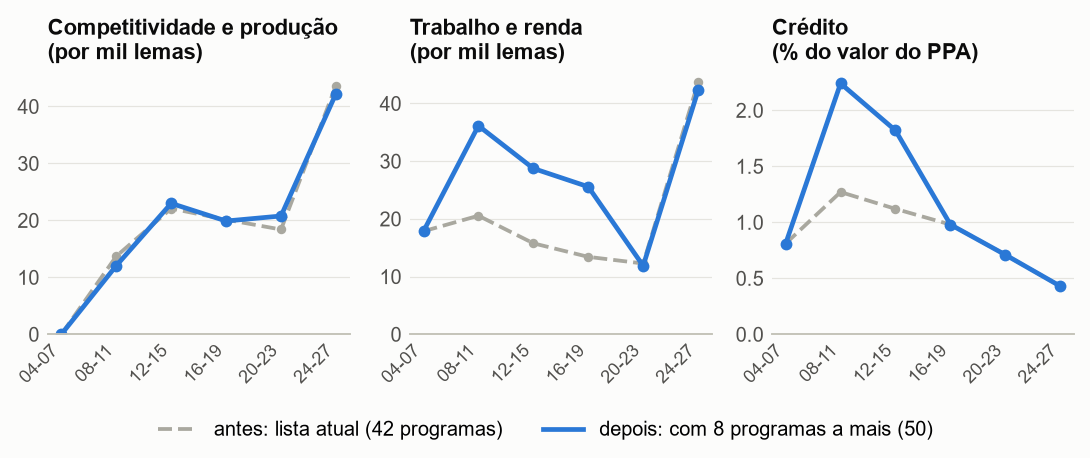

In [10]:
fig("doc_cenario.png")

Acima: a lista atual contra a lista com **3 programas a mais (8 pares)**: 0530 Pró-Emprego e Renda (2008-2019), 0101 Acelera Santa Catarina (2012-2027) e 0204 Missões, Recepções e Eventos Internacionais (2016-2019). O classificador apontou 5 desses pares; os outros 3 foram acrescentados para completar as séries. Competitividade não muda; "trabalho e renda" e a parcela do orçamento mudam.

In [11]:
fora = r[r.teste.isin(["selecionados | dimensão", "PPA inteiro | dimensão", "não selecionados | dimensão"])]
tabela(fora[["teste", "documentos"] + [f"{p} taxa" for p in PER] + ["p_amplitude"]]
       .rename(columns={**{f"{p} taxa": p[2:4] + "-" + p[-2:] for p in PER}, "p_amplitude": "p variação"}), 1)

teste,documentos,04-07,08-11,12-15,16-19,20-23,24-27,p variação
selecionados | dimensão,42,"0,0","13,7","22,1","20,1","18,4","43,6","0,005"
PPA inteiro | dimensão,514,"3,0","5,6","4,7","4,2","4,7","6,4","0,717"
não selecionados | dimensão,472,"3,2","4,7","2,2","2,2","3,0","2,4","0,744"


**Leitura:** nenhum programa isolado produz o resultado, e a lista é quase a mesma de 2008 a 2027. Mas **no PPA inteiro a competitividade não sobe** (p = 0,72), e fora da lista fica estável. A alta é específica dos programas de política industrial: o discurso se concentrou nela, ou a seleção favoreceu esse vocabulário. Os testes reduzem esse risco, mas não o eliminam.

## 6. Instrumentos: crédito, APL, incubadoras

*Combinados: ligar as palavras que mudaram a tipos de política; achar APLs, clusters e educação tecnológica e como são promovidos.*

O discurso sobe, o orçamento desce. 
Valores orçados das subações (ações dos programas), em % do orçamento total do próprio PPA (2004-2007 e 2008-2011 trazem só um ano; por isso a comparação é em %). Dois ajustes:
- **folha da EPAGRI e emendas parlamentares** tiradas: a folha estava em programas de pessoal até 2019 (0850, Gestão de Pessoas) e passou para o 0310 em 2020, ou seja, o aumento de 2020-2027 era contábil;
- **crédito a empresas** separado do crédito a prefeituras ("Apoio creditício ao desenvolvimento dos municípios", a maior linha do BADESC).

In [12]:
o = pd.read_csv(S / "orcamento_ajustado.csv")
tabela(pd.DataFrame({
    "PPA": o.periodo,
    "política industrial (% do PPA)": o.pct_selecionados,
    "sem pessoal e emendas (%)": o.pct_selecionados_sem_pessoal_emendas,
    "crédito total (%)": o.pct_credito_total,
    "crédito a empresas (%)": o.pct_credito_empresas,
    "crédito a empresas (R$ mi)": o.credito_empresas / 1e6}), 2)

PPA,política industrial (% do PPA),sem pessoal e emendas (%),crédito total (%),crédito a empresas (%),crédito a empresas (R$ mi)
2004-2007,"3,07","3,07","0,81","0,52","90,91"
2008-2011,"3,16","3,16","1,27","0,80","208,29"
2012-2015,"2,08","2,08","1,12","0,52","661,59"
2016-2019,"1,78","1,78","0,98","0,65","886,29"
2020-2023,"2,41","1,37","0,71","0,39","723,37"
2024-2027,"2,50","1,21","0,43","0,30","803,76"


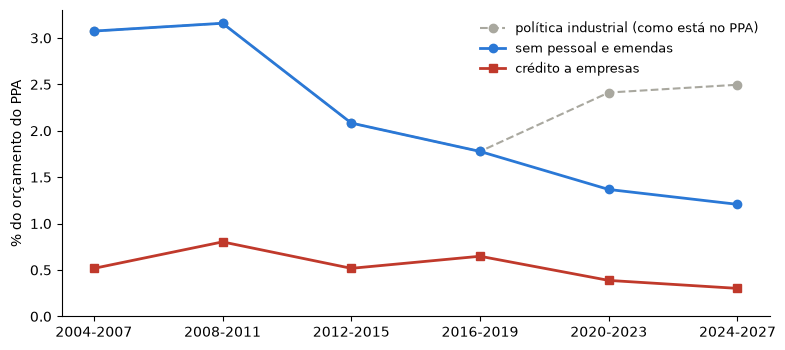

In [13]:
fig_, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(PER, o.pct_selecionados, "o--", color="#a9a89f", label="política industrial (como está no PPA)")
ax.plot(PER, o.pct_selecionados_sem_pessoal_emendas, "o-", color="#2a78d6", lw=2, label="sem pessoal e emendas")
ax.plot(PER, o.pct_credito_empresas, "s-", color="#c0392b", lw=2, label="crédito a empresas")
ax.set_ylabel("% do orçamento do PPA"); ax.set_ylim(0, None); ax.legend(frameon=False, fontsize=9)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

**Leitura:** sem pessoal e emendas, a parcela da política industrial cai sem parar (3,2% em 2008-2011 para 1,2% em 2024-2027), e o crédito a empresas vai de 0,80% para 0,30%. Nos nomes das ações, a dimensão competitividade aparece 5 vezes, nenhuma depois de 2015. APL aparece como ação até 2012-2015; incubadoras e parques, até 2016-2019; incentivo fiscal, nunca. Qualificação é quase só de gestores públicos e agricultores; ensino técnico quase não aparece.

**Limites:** o PPA só registra o crédito que passa pelo orçamento do Estado (o BADESC também opera com recursos próprios, fundos e captação externa); a renúncia de ICMS fica fora do PPA e aparece na LDO; na LDO de 2025, cerca de R$ 24 bilhões por ano, sendo uns R$ 8 bilhões do setor Indústria.

## 7. ODS: o vocabulário da Agenda 2030 não cresce

*Combinado: ver se SC usa os ODS.*

Vocabulário de cada ODS = termos mais característicos das 169 metas oficiais (TF-IDF contra os outros 16, menos os genéricos). Comparação 2004-2015 x 2016-2027, com 3.000 permutações.

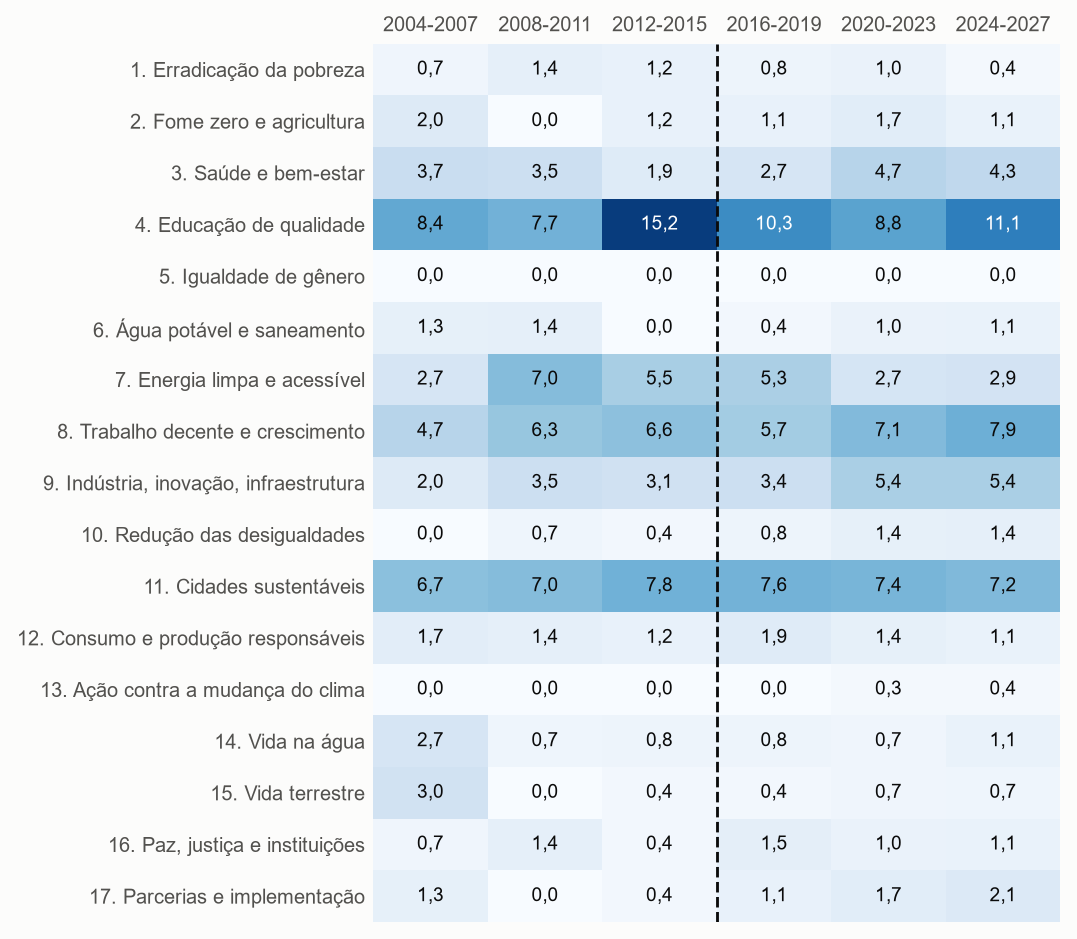

In [14]:
fig("doc_ods.png", 640)

In [15]:
a = pd.read_csv(S / "ods_antes_depois.csv", dtype={"ods": str})
a = a[(a.corpus == "PPA inteiro") & a.ods.isin(["9", "10", "17", "todos os ODS"])]
tabela(a[["ods", "titulo", "taxa_2004_2015", "taxa_2016_2027", "p_perm"]].fillna("")
       .rename(columns={"titulo": "título", "taxa_2004_2015": "2004-2015", "taxa_2016_2027": "2016-2027", "p_perm": "p"}), 2)

ods,título,2004-2015,2016-2027,p
9,"Indústria, inovação e infraestrutura","2,72","4,77","0,092"
10,Redução das desigualdades,"0,29","1,19","0,072"
17,Parcerias e meios de implementação,"0,72","1,67","0,082"
todos os ODS,,"42,35","46,42","0,345"


**Leitura:** nada cresce de forma significativa depois de 2015. O ODS 9 (p = 0,09) não é nem tendência com 17 testes (Bonferroni: 0,003). Pela similaridade de vetores (no PPA inteiro), o ODS 9 é o mais próximo de 43% dos programas selecionados contra 8% dos demais, coerente com a curadoria, mas não é validação independente: depende do corpus de referência e, só nos 42 pares, o ODS 9 empata com o ODS 16.

## 8. Clusterização e LDA: o que não se sustentou

*Combinado: clusterizar os termos antes do topic modeling.*

| Teste | Resultado |
|---|---|
| Mesmas palavras, sementes diferentes (10 palavras por tópico, Jaccard) | Os tópicos mudam a cada rodada |
| Clusterização prévia das palavras (sugestão do Dominik) | Estável entre sementes (cosseno 0,81 a 0,92), mas os clusters em si são fracos (silhueta de 0,09 a 0,14) |
| Um programa a mais no corpus (0530 de 2004-2007) | A clusterização muda por inteiro (ARI 0,46) e os tópicos somem |

Causa: cerca de 1.500 lemas em 42 documentos. Proposta: registrar como teste feito e usar o índice por dimensão, que pode ser testado contra o acaso.

## 9. Metodologia

*Combinados: figura conceitual de como o texto é classificado; separar programa de seção.*

**Programa** é a unidade de política: cada programa do PPA (código de 4 dígitos) é classificado como política industrial ou não. **Seção** é o campo do texto dentro do programa (objetivo, justificativa, ações): é estrutura do documento, não classificação.

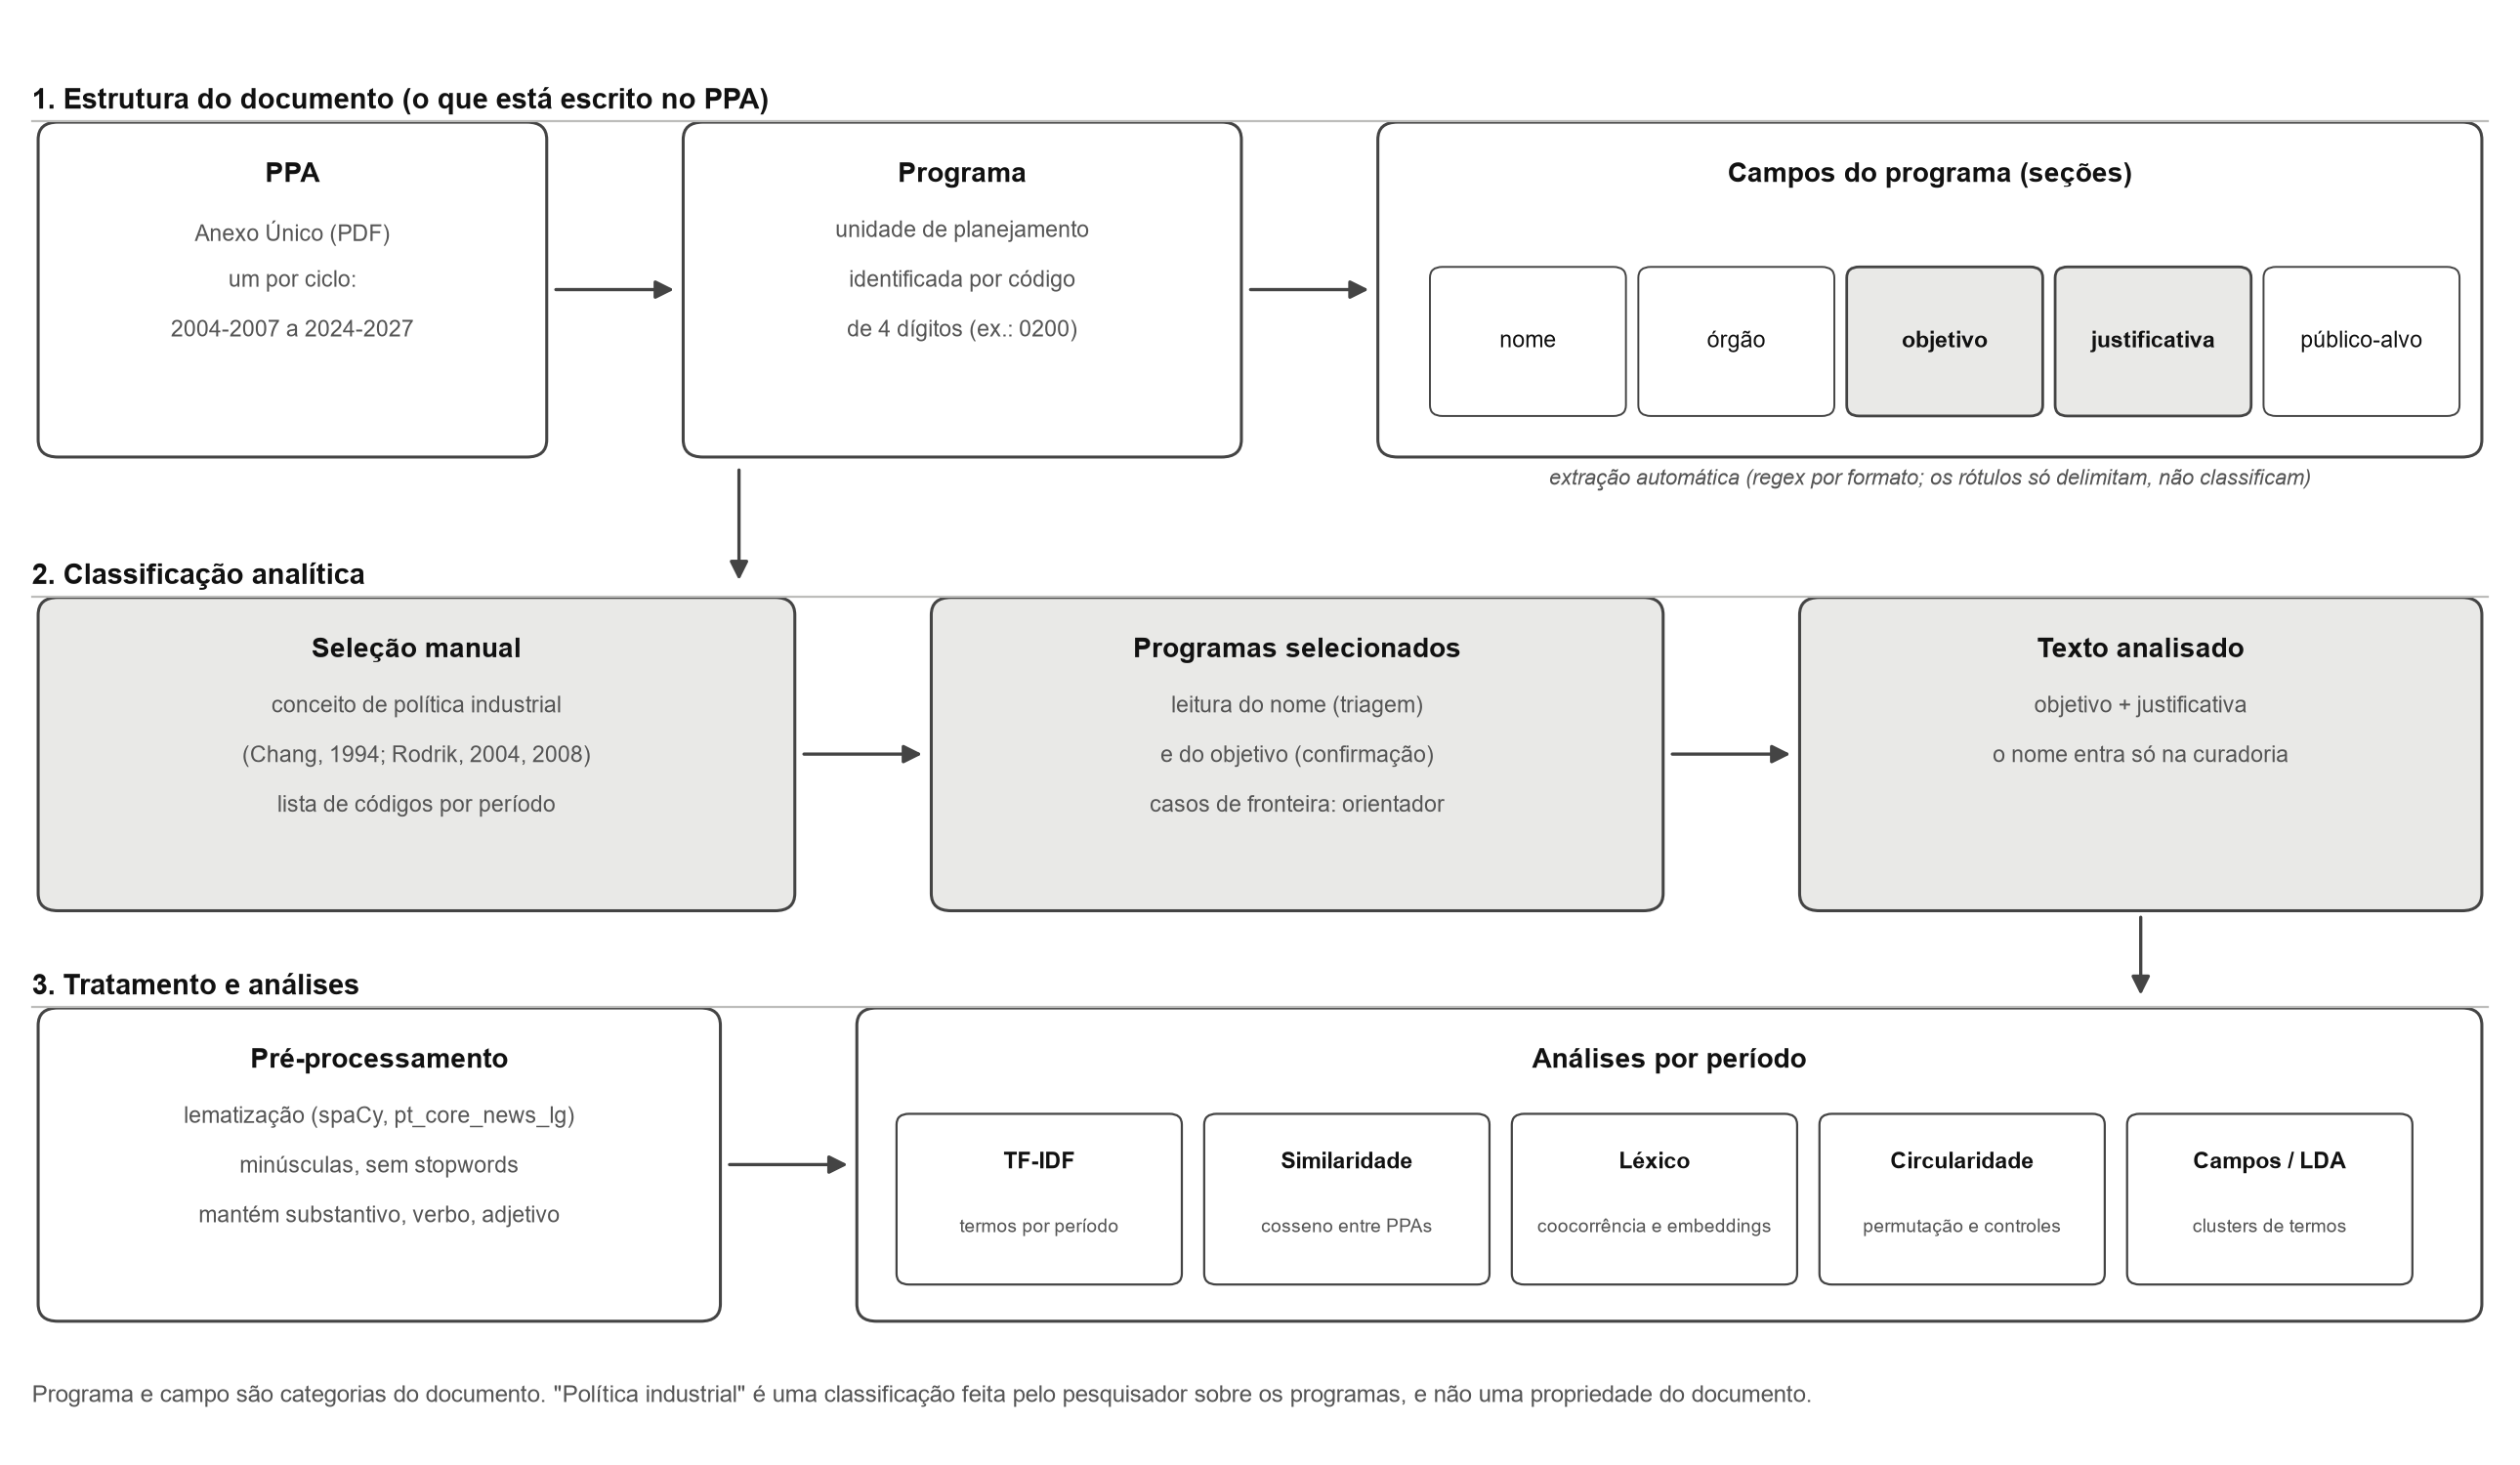

In [16]:
fig("figura_conceitual_metodo.png")

## 10. Para decidir na reunião

- **Recorte:** ficar no Estado ou ir para as microrregiões?
- **Setores:** testar se a política industrial de SC (PPA, incentivos da LDO e crédito) mira setores complexos ou setores em que SC já é forte.

1. **Ponte com o ICE das microrregiões** (decisão principal): orçamento regionalizado das SDRs (2004-2015) ou caminho setorial à la Juhász. Regressão ou análise descritiva?
2. **Contexto histórico:** cruzar a alta de 2024-2027 com a troca de governo de 2023.
3. **Lista de programas:** 0250 (Inclusão Digital), 0212 (Comércio Exterior), 0354 (Trabalho, Emprego e Renda), 0210 (quase todo emendas em 2024-2027) e os 3 do classificador.
4. **Léxico:** juntar digital à inovação; "renda" e "trabalho" são genéricas; nova rodada de expansão? Segunda pessoa avaliando os 38 candidatos (concordância).
5. **LDA:** sai dos resultados ou fica como registro metodológico?
6. **Orçamento:** buscar o crédito do BADESC fora do orçamento e a renúncia de ICMS (LDO)?
7. **Benchmark com outras UFs:** trabalho futuro.